In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
df = load_wine(as_frame=True)
X = df.data
y = df.target

In [3]:
print("Dataset shape:", X.shape)
print("Wine classes:", df.target_names)

X.head()

Dataset shape: (178, 13)
Wine classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 142
Testing records: 36


In [5]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [6]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
results.head(10)

,Actual,Predicted
0,0,0
1,2,2
2,0,0
3,1,1
4,1,1
5,0,0
6,0,0
7,1,0
8,1,1
9,2,2


In [7]:
accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", round(accuracy, 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=df.target_names))

Test accuracy: 0.972

Classification report:
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



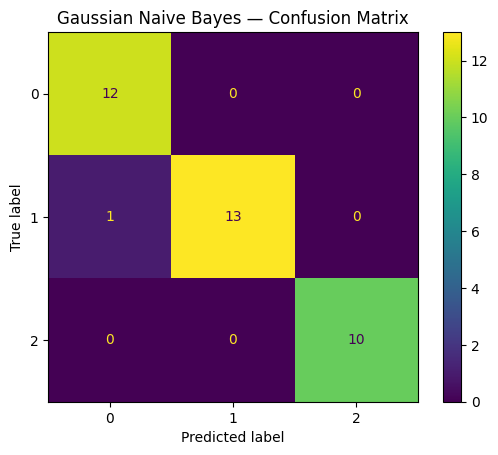

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
)
plt.title("Gaussian Naive Bayes — Confusion Matrix")
plt.show()

In [9]:
one_record = X_test.iloc[[0]]

predicted_class = model.predict(one_record)[0]
actual_class = y_test.iloc[0]

print("Actual class:", df.target_names[actual_class])
print("Predicted class:", df.target_names[predicted_class])

Actual class: class_0
Predicted class: class_0


In [10]:
probabilities = model.predict_proba(one_record)

pd.DataFrame(probabilities, columns=df.target_names).round(3)

,class_0,class_1,class_2
0,1.0,0.0,0.0
